# Módulo 49: Diseño de dashboards — Solución
*Juliho Castillo*

Enunciado para estudiantes: [m49-diseno-de-dashboards-guia.ipynb](m49-diseno-de-dashboards-guia.ipynb) · Lección: [m49-diseno-de-dashboards-leccion.ipynb](m49-diseno-de-dashboards-leccion.ipynb)

## Contexto

Las páginas de los Módulos 46 a 48 se reúnen en una sola app de Streamlit con tema común, portada con menú, botón de inicio en todas las páginas y marcadores para los dos semestres de 2019. La app resultante es la de [`../practica-ventas/`](../practica-ventas/): [`app.py`](../practica-ventas/app.py), las páginas de [`paginas/`](../practica-ventas/paginas/), [`estilo.py`](../practica-ventas/estilo.py) y [`comun.py`](../practica-ventas/comun.py). Se lanza desde la raíz del repositorio con `uv run streamlit run s08-dashboards/practica-ventas/app.py`. El enunciado original del curso se perdió; las instrucciones de la guía se reconstruyeron a partir de la solución.

In [1]:
import sys
from pathlib import Path

import plotly.express as px
import plotly.io as pio
import streamlit.config
import streamlit.logger
from streamlit.testing.v1 import AppTest

pio.renderers.default = "png"
pio.defaults.default_width = 900
pio.defaults.default_height = 450
# Sin mensajes del registro de Streamlit en las salidas (los errores se leen con at.exception)
streamlit.config.set_option("logger.level", "critical")
streamlit.logger.set_log_level("CRITICAL")

PRACTICA = Path("../practica-ventas").resolve()
sys.path.insert(0, str(PRACTICA))
import estilo
import ventas as practica

con = practica.conectar()

import tomllib

APP = str(PRACTICA / "app.py")

### Tarea 1. Tema y estilo

{'base': 'light', 'primaryColor': '#2a78d6', 'backgroundColor': '#fcfcfb', 'textColor': '#0b0b0b'}
Plantilla: plotly_white+ventas | colores por categoría: {'Technology': '#2a78d6', 'Furniture': '#eb6834', 'Office Supplies': '#1baf7a'}


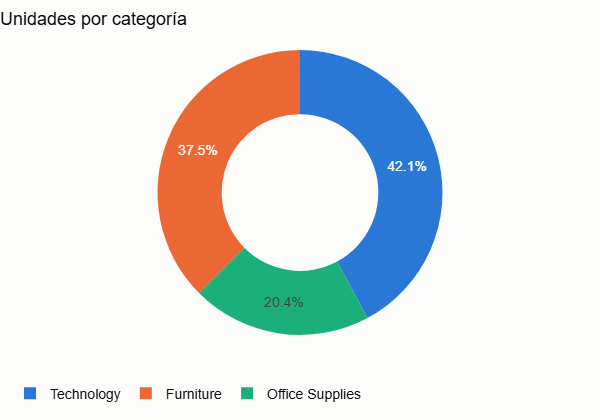

In [2]:
tema = tomllib.loads(Path("../../.streamlit/config.toml").read_text(encoding="utf-8"))["theme"]
print({clave: tema[clave] for clave in ["base", "primaryColor", "backgroundColor", "textColor"]})

# La plantilla de Plotly repite los colores del tema
assert tema["primaryColor"] == estilo.PRIMARIO
assert tema["backgroundColor"] == estilo.FONDO
assert tema["chartCategoricalColors"] == estilo.PALETA
print("Plantilla:", pio.templates.default, "| colores por categoría:", estilo.COLORES_CATEGORIA)

categorias = practica.ventas_por(con, "categoria")
anillo = px.pie(categorias, names="categoria", values="cantidad_total", hole=0.55, color="categoria",
                color_discrete_map=estilo.COLORES_CATEGORIA, title="Unidades por categoría")
anillo.update_traces(sort=False)
anillo.update_layout(width=600, height=420)
anillo.show()

El tema de `config.toml` (base clara, primario azul `#2a78d6`) y la plantilla `ventas` de `estilo.py` comparten los mismos colores, y una comprobación con `assert` impide que se separen. Cada categoría tiene un color fijo, el mismo en el anillo del resumen y en el mapa de árbol del análisis, aunque un filtro quite alguna.

### Tarea 2. Portada con menú

In [3]:
texto = (PRACTICA / "app.py").read_text(encoding="utf-8")
print(texto.split(chr(34) * 3, 2)[2].strip())  # sin el docstring del módulo

from pathlib import Path

import streamlit as st

import comun
import estilo  # noqa: F401  (registra la plantilla de Plotly)
import seguridad

RUTA = Path(__file__).resolve().parent

st.set_page_config(page_title="Ventas", page_icon=":material/storefront:", layout="wide")
st.logo(str(RUTA / "icono-inicio.jpg"), size="large")

inicio = st.Page("paginas/inicio.py", title="Inicio", icon=":material/home:", default=True)
paginas = {
    "": [inicio],
    "Tablero": [
        st.Page("paginas/resumen.py", title="Resumen", icon=":material/dashboard:"),
        st.Page("paginas/medidas.py", title="Medidas de tiempo", icon=":material/calendar_month:"),
        st.Page("paginas/analisis.py", title="Análisis por país", icon=":material/travel_explore:"),
    ],
    "Información": [
        st.Page("paginas/acerca.py", title="Acerca de", icon=":material/info:"),
    ],
}
pagina = st.navigation(paginas, position="sidebar")

with st.sidebar:
    seguridad.panel_acceso()
    comun.barra_lateral()

# 

In [4]:
at = AppTest.from_file(APP, default_timeout=90).run()
print("Excepciones:", len(at.exception))
print("Título de la portada:", at.title[0].value)
print("Menú:", [enlace.value for enlace in at.page_link])
print("Accesos rápidos:", [b.label for b in at.button if b.key and b.key.startswith("inicio_")])

Excepciones: 0
Título de la portada: Dashboard de ventas
Menú: ['Resumen', 'Análisis por país', 'Medidas de tiempo', 'Acerca de']
Accesos rápidos: ['Resumen de 2019, primer semestre', 'Resumen de 2019, segundo semestre']


`st.navigation` organiza las cinco páginas en tres secciones (sin título para la portada, "Tablero" e "Información"). La portada es la página por defecto; `st.logo` coloca `icono-inicio.jpg` arriba de la barra lateral en todas las páginas, y el menú tiene una tarjeta con `st.page_link` por página. La página "Acerca de" lleva el autor, las fuentes y cómo se construyó la app.

### Tarea 3. Botón de inicio

In [5]:
for pagina in ["paginas/resumen.py", "paginas/medidas.py", "paginas/analisis.py", "paginas/acerca.py"]:
    at.switch_page(pagina).run()
    primer_enlace = at.page_link[0].value
    print(f"{pagina:22} excepciones: {len(at.exception)} | primer enlace: {primer_enlace} | título: {at.title[0].value}")

paginas/resumen.py     excepciones: 0 | primer enlace: Inicio | título: Resumen de ventas


paginas/medidas.py     excepciones: 0 | primer enlace: Inicio | título: Medidas de tiempo


paginas/analisis.py    excepciones: 0 | primer enlace: Inicio | título: Análisis por país
paginas/acerca.py      excepciones: 0 | primer enlace: Inicio | título: Acerca de este dashboard


El enlace "Inicio" se escribe en `app.py`, justo antes de `pagina.run()`, salvo cuando la página es la propia portada. Así aparece en todas las demás páginas y siempre en el mismo lugar, sin repetir código en cada una.

### Tarea 4. Marcadores y navegación

In [6]:
esperado = {
    "2019-s1": practica.kpis(con, desde="2019-01-01", hasta="2019-06-30")["ventas_total"],
    "2019-s2": practica.kpis(con, desde="2019-07-01", hasta="2019-12-31")["ventas_total"],
    "todo": practica.kpis(con)["ventas_total"],
}
at = AppTest.from_file(APP, default_timeout=90).run()
at.switch_page("paginas/resumen.py").run()
for clave, total in esperado.items():
    at.button(key=f"marcador_{clave}").click().run()
    activo = [b.label for b in at.button if b.proto.type == "primary"]
    print(f"{clave:8} ventas {at.metric[0].value:>12} (esperado {estilo.millones(total)}) | "
          f"URL {dict(at.query_params)} | activo {activo}")
    assert at.metric[0].value == estilo.millones(total)

2019-s1  ventas   6 805.18 M (esperado 6 805.18 M) | URL {'marcador': '2019-s1'} | activo ['2019, primer semestre']


2019-s2  ventas   7 223.00 M (esperado 7 223.00 M) | URL {'marcador': '2019-s2'} | activo ['2019, segundo semestre']


todo     ventas  41 940.96 M (esperado 41 940.96 M) | URL {} | activo ['Todo el periodo']


In [7]:
# Un enlace con ?marcador= abre la app con ese periodo
compartido = AppTest.from_file(APP, default_timeout=90)
compartido.query_params["marcador"] = "2019-s1"
compartido.run()
compartido.switch_page("paginas/resumen.py").run()
print("Desde", compartido.session_state["desde"], "hasta", compartido.session_state["hasta"],
      "| ventas", compartido.metric[0].value)

# Restablecer filtros
compartido.multiselect(key="paises_sel").set_value(["PERU"]).run()
print("Con PERU:", compartido.metric[0].value)
next(b for b in compartido.button if b.label == "Restablecer filtros").click().run()
print("Tras restablecer:", compartido.metric[0].value, "| países:", compartido.session_state["paises_sel"])

Desde 2019-01-01 hasta 2019-06-30 | ventas 6 805.18 M


Con PERU: 343.45 M


Tras restablecer: 41 940.96 M | países: []


Cada botón de marcador fija `desde` y `hasta` con un callback y escribe `?marcador=` en la URL; el activo se dibuja con `type="primary"`. El primer semestre de 2019 vendió 6 805.18 M y el segundo 7 223.00 M. Un enlace con `?marcador=2019-s1` abre la app con ese periodo, y "Restablecer filtros" vuelve al periodo completo (41 940.96 M) y vacía los países elegidos.

### Tarea 5. Revisión final y descarga

In [8]:
at = AppTest.from_file(APP, default_timeout=90).run()
excepciones = {"paginas/inicio.py": len(at.exception)}
for pagina in ["paginas/resumen.py", "paginas/medidas.py", "paginas/analisis.py", "paginas/acerca.py"]:
    at.switch_page(pagina).run()
    excepciones[pagina] = len(at.exception)
print(excepciones)

at.switch_page("paginas/resumen.py").run()
descargas = at.get("download_button")
print("Botones de descarga en el resumen:", [d.proto.label for d in descargas])
csv = practica.tabla_por_pais(con).to_csv(index=False)
print(csv.splitlines()[0])
print(csv.splitlines()[1])

{'paginas/inicio.py': 0, 'paginas/resumen.py': 0, 'paginas/medidas.py': 0, 'paginas/analisis.py': 0, 'paginas/acerca.py': 0}


Botones de descarga en el resumen: ['Descargar tabla (CSV)']
pais,iso3,ventas_mediana,ventas_total,cantidad_total,pct_cantidad,ventas_promedio
FRANCE,FRA,22747.0,6709452115,14882353,0.10051855388206692,44566.27110594487


Ninguna página lanza excepciones. El resumen ofrece la tabla por país en CSV con `st.download_button`, que sustituye a la exportación a PDF. En una ventana estrecha, las columnas se apilan en el orden del script (KPIs, mapa, anillo, tendencia y tabla), que es el orden de importancia; la captura de la [lección](m49-diseno-de-dashboards-leccion.ipynb) lo muestra a 420 píxeles de ancho.

**Revisión posterior (2026-10):** El ejercicio se resolvió originalmente en Power BI (tema, navegadores de páginas y de marcadores, botones con acciones y exportación a PDF). Se rehízo en Python con Streamlit (`st.navigation`, `st.page_link`, `st.session_state`, `st.query_params`) y Plotly para que la sección no dependa de software de pago ni de Windows; la versión original sigue en el historial de git.